# Análisis de resultados

Lee los JSON que escriben `lab03 train` y `lab03 evaluate`, compara las variantes
(modelo base, AHCL y ablaciones) y analiza los errores del modelo elegido.

Cada run es un directorio `runs/<nombre>/` con:

- `config.json`: variante del modelo e hiperparámetros.
- `history.json`: pérdidas, clusters y métricas de validación por época.
- `best_testing.json`: métricas en test de `best.pt` (`lab03 evaluate runs/<nombre>/best.pt`).

Comandos para generarlos:

```sh
uv run lab03 train --out runs/ahcl                                 # AHCL (paper)
uv run lab03 train --no-capf --loss-weight 1 --out runs/baseline   # modelo base
uv run lab03 train --no-spatial-attention --out runs/abl_no_sa     # ablación
uv run lab03 train --no-se --out runs/abl_no_se                    # ablación
uv run lab03 train --loss-weight 0 --out runs/abl_only_ccl         # ablación
uv run lab03 evaluate runs/<nombre>/best.pt                        # test
```

In [1]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
from cycler import cycler
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator
from torch.utils.data import DataLoader

from lab03.analysis import load_runs, markdown_table, report_table, validation_table
from lab03.evaluate import (
    extract_features,
    pairwise_distance,
    score_queries,
    valid_ranking,
)
from lab03.main import get_device, load_checkpoint, split_datasets

## Parámetros

In [2]:
CWD = Path.cwd().resolve()
PROJECT_ROOT = next(
    path for path in (CWD, *CWD.parents) if (path / "pyproject.toml").is_file()
)
DATA_DIR = PROJECT_ROOT / "data"
RUNS_DIR = PROJECT_ROOT / "runs"

REFERENCE_RUN = "ahcl"  # las diferencias de la sección 3 son contra este run
# Modelo para el análisis de errores (sección 4): el elegido en validación.
CHECKPOINT = RUNS_DIR / "capf_fix_a1" / "best.pt"

# Las curvas se dibujan por grupo, para no repetir colores en una figura. Las
# referencias aparecen en todos los grupos con el mismo color.
REFERENCES = ["ahcl", "baseline"]
GROUPS = {
    "Ronda 1 · ablación de AHCL": ["abl_no_sa", "abl_no_se", "abl_only_ccl"],
    "Ronda 2 · resolución y peso a": ["ahcl_256", "baseline_256", "baseline_a05"],
    "Ronda 3 · CAPF corregido": [
        "capf_fix",
        "capf_fix_a1",
        "capf_fix_id",
        "capf_fix_bal",
    ],
}
SPLIT = "testing"
NUM_WORKERS = 0  # >0 acelera la extracción, pero en macOS + Jupyter puede fallar

In [3]:
# Paleta categórica en orden fijo (nunca reciclada dentro de una figura).
SERIES = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
CONDITIONS = {
    "query": ("Original 128×64", SERIES[0]),
    "low_res": ("Baja resolución 32×16", SERIES[1]),
}
SHORT = {"query": "Original", "low_res": "Baja res."}
GOOD, CRITICAL = "#0ca30c", "#d03b3b"  # acierto / error, siempre con ✓ / ✗
INK, MUTED = "#0b0b0b", "#898781"

plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": cycler(color=SERIES),
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.8,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "lines.linewidth": 2,
        "lines.markersize": 6,
        "legend.frameon": False,
    }
)

## 1. Runs disponibles

In [4]:
runs = load_runs(RUNS_DIR)
by_name = {run.name: run for run in runs}
listed = set(REFERENCES).union(*GROUPS.values())
groups = dict(GROUPS)
if others := [run.name for run in runs if run.name not in listed]:
    groups["Otros"] = others
# Cada grupo con sus referencias delante: ahcl y baseline mantienen su color.
run_groups = {
    title: [by_name[name] for name in [*REFERENCES, *names] if name in by_name]
    for title, names in groups.items()
}
for title, members in run_groups.items():
    if len(members) > len(SERIES):
        print(f"{title}: {len(members)} runs, más que colores; divide el grupo.")

for run in runs:
    epochs = run.history[-1]["epoch"] if run.history else 0
    reports = ", ".join(run.reports) or "sin evaluar en test"
    print(f"{run.name:<16} {run.label:<48} {epochs:>3} épocas · {reports}")
if not runs:
    print(f"No hay runs con history.json en {RUNS_DIR}")

abl_no_sa        sin atención espacial                             50 épocas · best_testing
abl_no_se        sin SE                                            50 épocas · best_testing
abl_only_ccl     a=0                                               50 épocas · best_testing
ahcl             AHCL (paper)                                      50 épocas · best_testing
ahcl_256         256x128                                           50 épocas · best_testing
baseline         sin CAPF, a=1                                     50 épocas · best_testing
baseline_256     sin CAPF, a=1, 256x128                            50 épocas · best_testing
baseline_a05     sin CAPF                                          50 épocas · best_testing
capf_fix         atención desde identidad, GAP/GMP normalizados    50 épocas · best_testing
capf_fix_a1      atención desde identidad, GAP/GMP normalizados, a=1  50 épocas · best_testing
capf_fix_bal     GAP/GMP normalizados                              50 épocas 

## 2. Selección con validación

Para cada run, la época con mayor mAP de validación con queries originales: es
el `best.pt` que se evalúa en test. Las configuraciones se comparan aquí, sin
mirar el test. El conjunto de validación tiene solo 100 queries, así que
diferencias de 1–2 puntos de mAP están dentro del ruido.

In [5]:
display(Markdown(markdown_table(validation_table(runs))))

| run | variant | epoch | orig mAP | orig rank1 | orig rank5 | orig rank10 | low mAP | low rank1 | low rank5 | low rank10 | mAP drop | drop % |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| abl_no_sa | sin atención espacial | 10 | 28.0% | 42.0% | 57.0% | 66.0% | 15.6% | 26.0% | 39.0% | 46.0% | 12.4 pts | 44.4% |
| abl_no_se | sin SE | 15 | 14.9% | 23.0% | 32.0% | 36.0% | 9.2% | 13.0% | 23.0% | 34.0% | 5.7 pts | 38.4% |
| abl_only_ccl | a=0 | 10 | 15.4% | 27.0% | 43.0% | 47.0% | 8.3% | 12.0% | 23.0% | 36.0% | 7.1 pts | 46.2% |
| ahcl | AHCL (paper) | 20 | 14.7% | 25.0% | 35.0% | 39.0% | 6.0% | 10.0% | 22.0% | 30.0% | 8.7 pts | 59.2% |
| ahcl_256 | 256x128 | 10 | 7.1% | 16.0% | 21.0% | 23.0% | 2.1% | 3.0% | 8.0% | 12.0% | 5.0 pts | 70.5% |
| baseline | sin CAPF, a=1 | 25 | 34.1% | 53.0% | 64.0% | 72.0% | 18.2% | 21.0% | 37.0% | 47.0% | 15.9 pts | 46.7% |
| baseline_256 | sin CAPF, a=1, 256x128 | 35 | 33.2% | 44.0% | 56.0% | 62.0% | 23.0% | 31.0% | 48.0% | 56.0% | 10.2 pts | 30.8% |
| baseline_a05 | sin CAPF | 10 | 21.1% | 30.0% | 46.0% | 55.0% | 10.7% | 17.0% | 30.0% | 36.0% | 10.3 pts | 49.2% |
| capf_fix | atención desde identidad, GAP/GMP normalizados | 10 | 22.5% | 37.0% | 48.0% | 52.0% | 13.6% | 21.0% | 41.0% | 51.0% | 8.9 pts | 39.5% |
| capf_fix_a1 | atención desde identidad, GAP/GMP normalizados, a=1 | 30 | 38.3% | 62.0% | 69.0% | 76.0% | 18.4% | 27.0% | 42.0% | 50.0% | 19.9 pts | 51.9% |
| capf_fix_bal | GAP/GMP normalizados | 10 | 15.1% | 26.0% | 36.0% | 48.0% | 8.1% | 9.0% | 23.0% | 27.0% | 7.0 pts | 46.1% |
| capf_fix_id | atención desde identidad | 10 | 24.2% | 34.0% | 46.0% | 53.0% | 15.9% | 23.0% | 32.0% | 36.0% | 8.2 pts | 34.1% |

### Curvas de entrenamiento

Una figura por ronda de experimentos. `ahcl` y `baseline` se repiten en todas
como referencia.

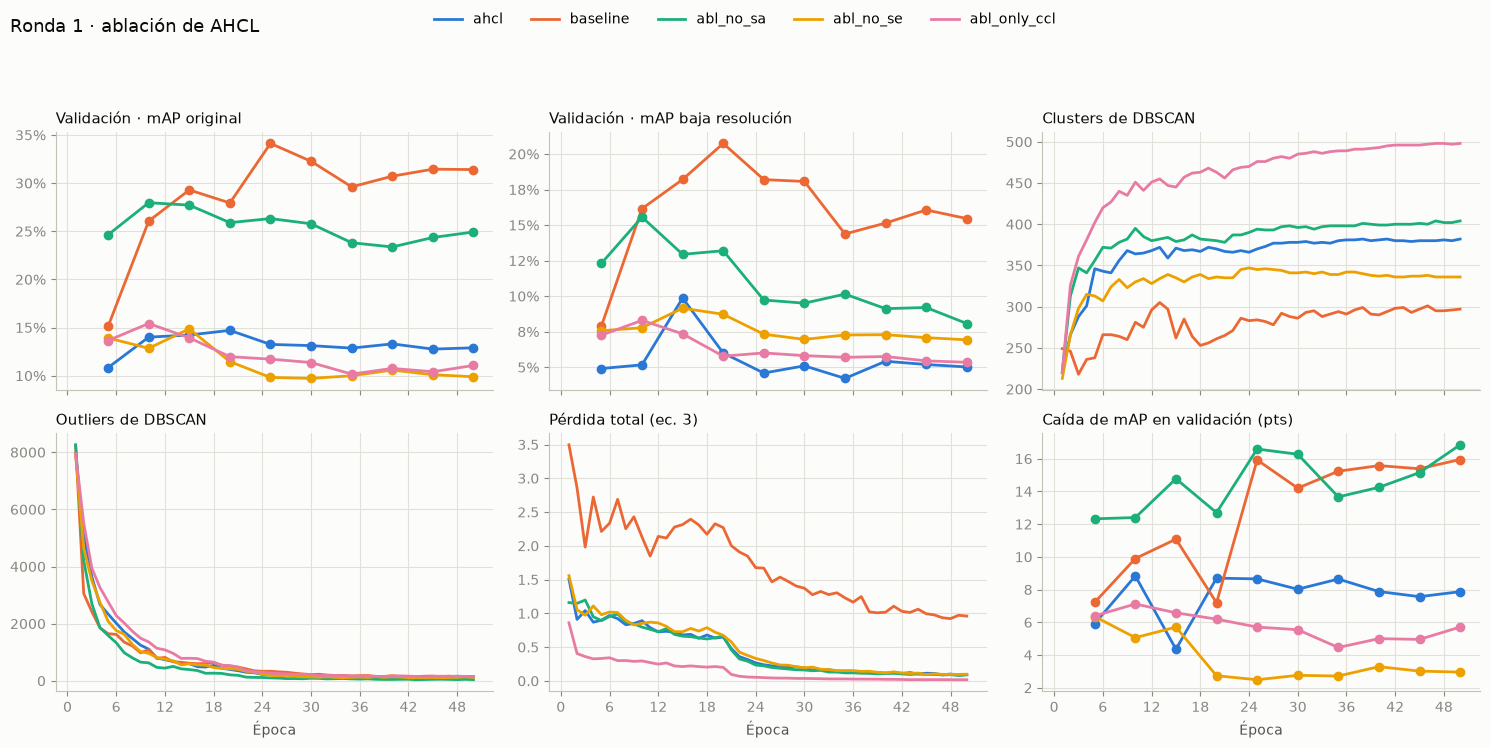

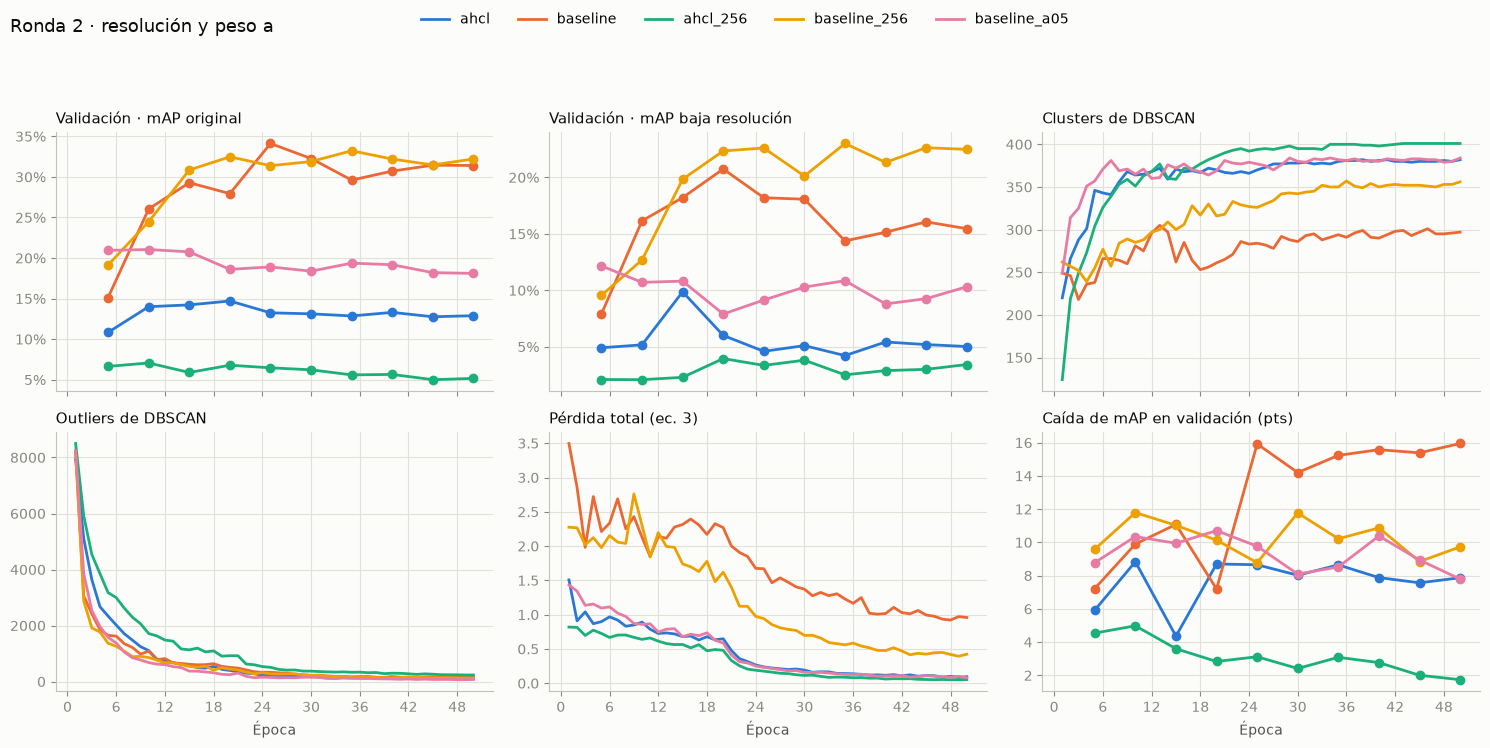

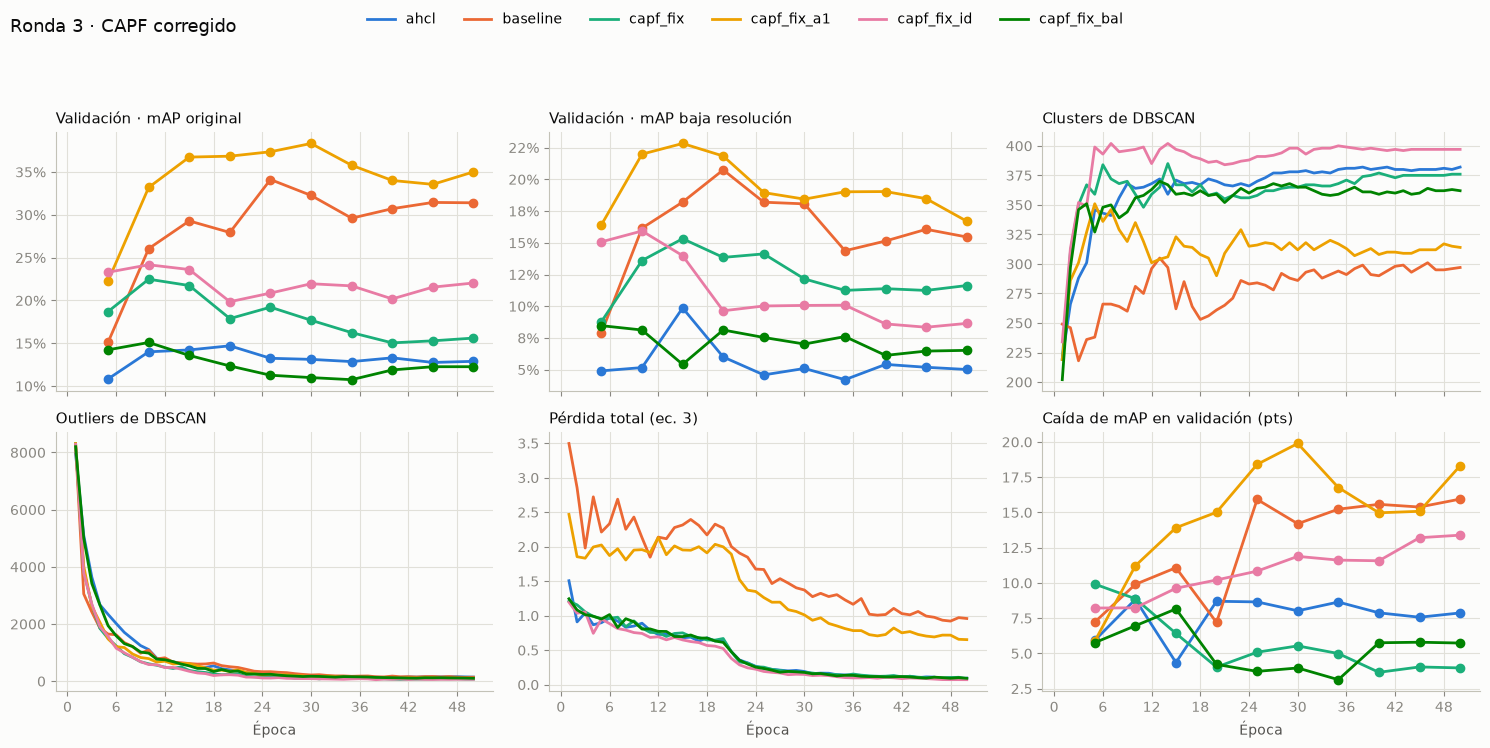

In [6]:
panels = [
    ("Validación · mAP original", lambda r: r["validation"]["query"]["mAP"], True),
    (
        "Validación · mAP baja resolución",
        lambda r: r["validation"]["low_res"]["mAP"],
        True,
    ),
    ("Clusters de DBSCAN", lambda r: r["num_clusters"], False),
    ("Outliers de DBSCAN", lambda r: r["num_outliers"], False),
    ("Pérdida total (ec. 3)", lambda r: r["losses"]["total"], False),
    (
        "Caída de mAP en validación (pts)",
        lambda r: 100 * r["validation"]["map_drop"]["absolute"],
        True,
    ),
]

for group, members in run_groups.items():
    if not members:
        continue
    fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
    for ax, (title, value, needs_validation) in zip(axes.flat, panels, strict=True):
        for color, run in zip(SERIES[: len(members)], members, strict=True):
            records = run.validated if needs_validation else run.history
            if not records:
                continue
            epochs = [r["epoch"] for r in records]
            marker = "o" if needs_validation else None
            ax.plot(
                epochs,
                [value(r) for r in records],
                marker=marker,
                color=color,
                label=run.name,
            )
        ax.set_title(title, loc="left", fontsize=11)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    for ax in axes[0, :2]:
        ax.yaxis.set_major_formatter("{x:.0%}")
    for ax in axes[1]:
        ax.set_xlabel("Época")
    handles, labels = axes.flat[2].get_legend_handles_labels()
    fig.suptitle(group, x=0.01, ha="left", fontsize=13, color=INK)
    fig.legend(handles, labels, loc="upper center", ncol=len(members))
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()

## 3. Resultados en test

Métricas de `best.pt` de cada run en las dos condiciones: queries originales y
queries de baja resolución, con la misma galería original. Se usa el mismo
modelo, embeddings normalizados L2 y similitud coseno.

In [7]:
test_rows = report_table(runs, split="testing")
display(Markdown(markdown_table(test_rows)))

| run | variant | orig mAP | orig rank1 | orig rank5 | orig rank10 | low mAP | low rank1 | low rank5 | low rank10 | mAP drop | drop % |
|---|---|---|---|---|---|---|---|---|---|---|---|
| abl_no_sa | sin atención espacial | 13.1% | 29.9% | 42.8% | 48.5% | 5.2% | 10.9% | 21.3% | 26.8% | 7.9 pts | 60.2% |
| abl_no_se | sin SE | 5.2% | 14.7% | 24.2% | 28.7% | 2.4% | 5.0% | 11.1% | 15.0% | 2.9 pts | 54.7% |
| abl_only_ccl | a=0 | 5.2% | 14.7% | 24.9% | 30.0% | 1.5% | 3.3% | 7.9% | 11.2% | 3.7 pts | 71.6% |
| ahcl | AHCL (paper) | 6.0% | 16.4% | 25.0% | 30.0% | 1.9% | 3.7% | 9.2% | 13.3% | 4.1 pts | 68.1% |
| ahcl_256 | 256x128 | 2.6% | 9.1% | 15.9% | 19.2% | 0.3% | 0.3% | 1.2% | 1.7% | 2.3 pts | 89.1% |
| baseline | sin CAPF, a=1 | 15.8% | 32.3% | 47.9% | 54.3% | 5.4% | 9.0% | 19.4% | 25.4% | 10.5 pts | 66.1% |
| baseline_256 | sin CAPF, a=1, 256x128 | 15.1% | 33.0% | 46.1% | 51.5% | 6.5% | 12.3% | 24.5% | 31.8% | 8.6 pts | 56.9% |
| baseline_a05 | sin CAPF | 8.8% | 21.9% | 34.1% | 39.5% | 2.5% | 4.4% | 10.0% | 14.5% | 6.3 pts | 71.4% |
| capf_fix | atención desde identidad, GAP/GMP normalizados | 10.0% | 24.5% | 35.4% | 40.7% | 3.7% | 7.7% | 16.2% | 21.6% | 6.3 pts | 62.8% |
| capf_fix_a1 | atención desde identidad, GAP/GMP normalizados, a=1 | 18.1% | 38.1% | 52.0% | 57.5% | 5.9% | 9.9% | 20.0% | 25.2% | 12.1 pts | 67.1% |
| capf_fix_bal | GAP/GMP normalizados | 6.6% | 18.0% | 27.7% | 32.1% | 1.8% | 3.5% | 8.8% | 12.7% | 4.8 pts | 73.0% |
| capf_fix_id | atención desde identidad | 11.6% | 27.2% | 38.8% | 44.3% | 4.7% | 9.1% | 18.3% | 23.7% | 6.9 pts | 59.2% |

### Modelo base y ablación frente a AHCL

In [8]:
reference = next((r for r in test_rows if r["run"] == REFERENCE_RUN), None)
if reference is None:
    print(f"Falta runs/{REFERENCE_RUN}/best_testing.json")
else:
    deltas = [
        {
            "run": row["run"],
            "variant": row["variant"],
            **{
                f"Δ {column} (pts)": f"{100 * (row[column] - reference[column]):+.1f}"
                for column in ("orig mAP", "orig rank1", "low mAP", "low rank1")
            },
        }
        for row in test_rows
        if row["run"] != REFERENCE_RUN
    ]
    display(Markdown(markdown_table(deltas)))

| run | variant | Δ orig mAP (pts) | Δ orig rank1 (pts) | Δ low mAP (pts) | Δ low rank1 (pts) |
|---|---|---|---|---|---|
| abl_no_sa | sin atención espacial | +7.1 | +13.5 | +3.3 | +7.2 |
| abl_no_se | sin SE | -0.8 | -1.6 | +0.5 | +1.3 |
| abl_only_ccl | a=0 | -0.9 | -1.7 | -0.5 | -0.4 |
| ahcl_256 | 256x128 | -3.5 | -7.3 | -1.6 | -3.4 |
| baseline | sin CAPF, a=1 | +9.8 | +15.9 | +3.4 | +5.3 |
| baseline_256 | sin CAPF, a=1, 256x128 | +9.1 | +16.6 | +4.6 | +8.6 |
| baseline_a05 | sin CAPF | +2.8 | +5.5 | +0.6 | +0.7 |
| capf_fix | atención desde identidad, GAP/GMP normalizados | +3.9 | +8.2 | +1.8 | +4.0 |
| capf_fix_a1 | atención desde identidad, GAP/GMP normalizados, a=1 | +12.1 | +21.8 | +4.0 | +6.2 |
| capf_fix_bal | GAP/GMP normalizados | +0.5 | +1.6 | -0.2 | -0.2 |
| capf_fix_id | atención desde identidad | +5.6 | +10.9 | +2.8 | +5.4 |

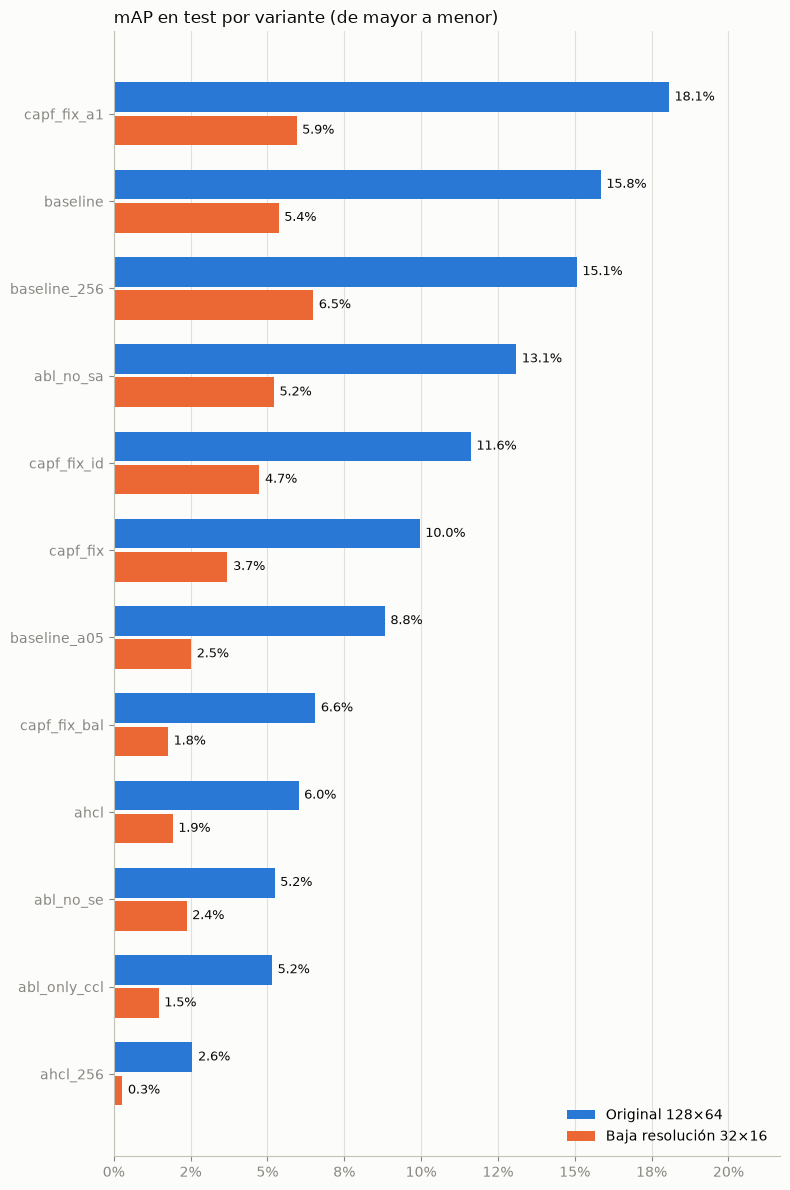

In [9]:
if test_rows:
    test_rows = sorted(test_rows, key=lambda row: -row["orig mAP"])
    names = [row["run"] for row in test_rows]
    y = np.arange(len(names))
    height = 0.38
    fig, ax = plt.subplots(figsize=(8, 0.9 * len(names) + 1.2))
    for offset, (prefix, condition) in zip(
        (-height / 2, height / 2), (("orig", "query"), ("low", "low_res")), strict=True
    ):
        label, color = CONDITIONS[condition]
        values = [row[f"{prefix} mAP"] for row in test_rows]
        # Barras finas con un hueco de superficie entre las dos condiciones.
        bars = ax.barh(
            y + offset, values, height=height - 0.04, color=color, label=label
        )
        ax.bar_label(
            bars, labels=[f"{v:.1%}" for v in values], padding=4, color=INK, fontsize=9
        )
    ax.set_yticks(y, names)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter("{x:.0%}")
    ax.set_xlim(0, max(row["orig mAP"] for row in test_rows) * 1.2)
    ax.grid(axis="y", visible=False)
    ax.set_title("mAP en test por variante (de mayor a menor)", loc="left")
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()

## 4. Análisis de errores del modelo elegido

Extrae los embeddings de `CHECKPOINT` en `SPLIT` y calcula el AP y el rank del
primer acierto de cada query. Es un análisis a posteriori: no se usa para elegir
ni para ajustar el modelo.

In [10]:
assert CHECKPOINT.is_file(), f"No existe {CHECKPOINT}: ajusta CHECKPOINT arriba"
device = get_device()
model, model_args, image_size = load_checkpoint(CHECKPOINT)
model.to(device)
split_path = DATA_DIR / f"{SPLIT}.h5"
queries, gallery = split_datasets(split_path, image_size)


def loader(dataset):
    return DataLoader(dataset, batch_size=256, num_workers=NUM_WORKERS)


g_feats = extract_features(model, loader(gallery), device)
q_feats = {
    name: extract_features(model, loader(ds), device) for name, ds in queries.items()
}
q_pids, q_cams = queries["query"].person_ids, queries["query"].camera_ids
g_pids, g_cams = gallery.person_ids, gallery.camera_ids

dist = {name: pairwise_distance(f, g_feats).numpy() for name, f in q_feats.items()}
scores = {
    name: score_queries(d, q_pids, g_pids, q_cams, g_cams) for name, d in dist.items()
}
valid = scores["query"].valid  # depende solo de las etiquetas: igual en ambas

variant = f"{model_args or 'AHCL'} · {image_size[0]}x{image_size[1]}"
print(f"{CHECKPOINT.relative_to(PROJECT_ROOT)} · {SPLIT} · {variant}")
print(f"{valid.sum()} de {len(valid)} queries tienen un acierto válido en la galería")
for name, s in scores.items():
    first_hit = s.first_hit[valid]
    ranks = " ".join(f"R{k}={(first_hit < k).mean():.1%}" for k in (1, 5, 10))
    print(f"{CONDITIONS[name][0]}: mAP={s.ap[valid].mean():.1%} {ranks}")

runs/capf_fix_a1/best.pt · testing · {'capf': True, 'spatial_attention': True, 'se': True, 'identity_attention': True, 'balanced_fusion': True} · 128x64
3368 de 3368 queries tienen un acierto válido en la galería
Original 128×64: mAP=18.1% R1=38.1% R5=52.0% R10=57.6%
Baja resolución 32×16: mAP=5.9% R1=9.9% R5=20.1% R10=25.2%


### Distribución del AP por query

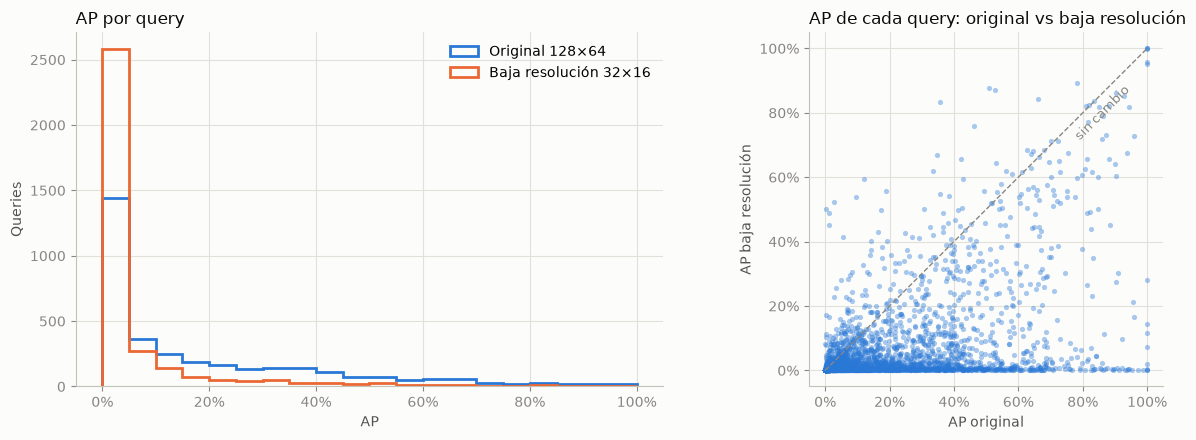

Caída media de AP por query: 12.1 pts
Queries que pierden más de 25 pts de AP: 19.5%
Queries que mejoran con baja resolución: 13.2%


In [11]:
ap = {name: s.ap[valid] for name, s in scores.items()}

fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.linspace(0, 1, 21)
for name, values in ap.items():
    label, color = CONDITIONS[name]
    left.hist(values, bins=bins, histtype="step", linewidth=2, color=color, label=label)
left.set_title("AP por query", loc="left")
left.set_xlabel("AP")
left.set_ylabel("Queries")
left.xaxis.set_major_formatter("{x:.0%}")
left.legend(loc="upper right")

right.scatter(
    ap["query"], ap["low_res"], s=14, alpha=0.4, color=SERIES[0], linewidths=0
)
right.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--")
right.annotate(
    "sin cambio",
    (0.86, 0.80),
    color=MUTED,
    fontsize=9,
    rotation=45,
    ha="center",
    va="center",
)
right.set_title("AP de cada query: original vs baja resolución", loc="left")
right.set_xlabel("AP original")
right.set_ylabel("AP baja resolución")
right.set_aspect("equal")
for axis in (right.xaxis, right.yaxis):
    axis.set_major_formatter("{x:.0%}")
fig.tight_layout()
plt.show()

ap_drop = ap["query"] - ap["low_res"]
print(f"Caída media de AP por query: {ap_drop.mean() * 100:.1f} pts")
print(f"Queries que pierden más de 25 pts de AP: {(ap_drop > 0.25).mean():.1%}")
print(f"Queries que mejoran con baja resolución: {(ap_drop < 0).mean():.1%}")

### ¿Dónde aparece el primer acierto?

Rank del primer acierto válido. Una query en "> 10" no tiene ningún acierto entre
los 10 primeros resultados.

In [12]:
rows = []
for name, s in scores.items():
    first_hit = s.first_hit[valid]
    rows.append(
        {
            "condición": CONDITIONS[name][0],
            "rank 1": (first_hit == 0).mean(),
            "rank 2–5": ((first_hit >= 1) & (first_hit < 5)).mean(),
            "rank 6–10": ((first_hit >= 5) & (first_hit < 10)).mean(),
            "> 10": (first_hit >= 10).mean(),
        }
    )
display(Markdown(markdown_table(rows)))

| condición | rank 1 | rank 2–5 | rank 6–10 | > 10 |
|---|---|---|---|---|
| Original 128×64 | 38.1% | 13.9% | 5.5% | 42.4% |
| Baja resolución 32×16 | 9.9% | 10.2% | 5.1% | 74.8% |

### Sesgo de cámara en los errores de Rank-1

El aprendizaje no supervisado tiende a agrupar imágenes de la misma cámara, porque
comparten fondo e iluminación. Si es así, en los errores de Rank-1 el primer
resultado debería venir de la cámara de la query con más frecuencia que al azar.

In [13]:
def top1(name, indices):
    return np.array(
        [
            valid_ranking(dist[name][i], q_pids[i], q_cams[i], g_pids, g_cams)[0]
            for i in indices
        ],
        dtype=int,
    )


chance = np.mean([(g_cams == cam).mean() for cam in q_cams[valid]])
rows = []
for name, s in scores.items():
    errors = np.flatnonzero(valid & (s.first_hit > 0))
    first = top1(name, errors)
    rows.append(
        {
            "condición": CONDITIONS[name][0],
            "errores R1": len(errors),
            "top-1 de la cámara de la query": (g_cams[first] == q_cams[errors]).mean(),
            "galería en esa cámara (azar)": chance,
        }
    )
display(Markdown(markdown_table(rows)))

| condición | errores R1 | top-1 de la cámara de la query | galería en esa cámara (azar) |
|---|---|---|---|
| Original 128×64 | 2084 | 68.1% | 17.6% |
| Baja resolución 32×16 | 3036 | 47.3% | 17.6% |

### Consistencia del embedding entre resoluciones

Similitud coseno entre el embedding de cada query original y el de su versión de
baja resolución. Si la similitud es baja, el modelo no reconoce a la misma
persona en la versión de baja resolución, y debería perder más AP.

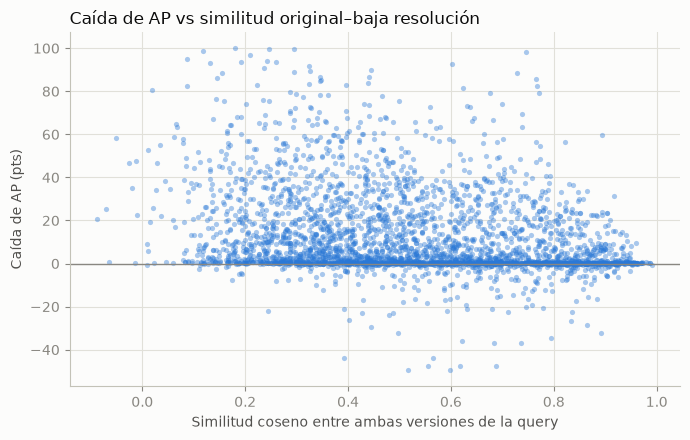

Similitud media: 0.529
Correlación de Spearman con la caída de AP: -0.32


In [14]:
consistency = (q_feats["query"] * q_feats["low_res"]).sum(dim=1).numpy()[valid]


def spearman(a, b):
    return np.corrcoef(a.argsort().argsort(), b.argsort().argsort())[0, 1]


fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(consistency, ap_drop * 100, s=14, alpha=0.4, color=SERIES[0], linewidths=0)
ax.axhline(0, color=MUTED, linewidth=1)
ax.set_title("Caída de AP vs similitud original–baja resolución", loc="left")
ax.set_xlabel("Similitud coseno entre ambas versiones de la query")
ax.set_ylabel("Caída de AP (pts)")
fig.tight_layout()
plt.show()

print(f"Similitud media: {consistency.mean():.3f}")
rho = spearman(consistency, ap_drop)
print(f"Correlación de Spearman con la caída de AP: {rho:.2f}")

### Ejemplos de recuperación

Top-10 de la galería en ambas condiciones. ✓ con marco verde es la misma persona y
✗ con marco rojo es otra persona. Sobre cada imagen se indica su cámara. Se omiten
las imágenes de la misma persona y cámara que la query, igual que en la métrica.

In [15]:
def show_rankings(q_index, k=10):
    fig, axes = plt.subplots(
        2, k + 1, figsize=(1.25 * (k + 1), 5.8), layout="constrained"
    )
    with h5py.File(split_path, "r") as file:
        keys = {"query": "query/images", "low_res": "query/images_low_resolution"}
        for row_axes, (name, key) in zip(axes, keys.items(), strict=True):
            row_axes[0].imshow(
                file[key][q_index].transpose(1, 2, 0), interpolation="nearest"
            )
            row_axes[0].set_title(
                f"{SHORT[name]}\nAP {scores[name].ap[q_index]:.0%}"
                f" · cam {q_cams[q_index]}",
                fontsize=9,
            )
            ranked = valid_ranking(
                dist[name][q_index], q_pids[q_index], q_cams[q_index], g_pids, g_cams
            )[:k]
            for ax, g in zip(row_axes[1:], ranked, strict=False):
                match = g_pids[g] == q_pids[q_index]
                ax.imshow(file["gallery/images"][g].transpose(1, 2, 0))
                ax.set_title(f"{'✓' if match else '✗'} cam {g_cams[g]}", fontsize=9)
                for spine in ax.spines.values():
                    spine.set_visible(True)
                    spine.set_edgecolor(GOOD if match else CRITICAL)
                    spine.set_linewidth(3)
    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    fig.suptitle(
        f"Query {q_index} · persona {q_pids[q_index]}", x=0.01, ha="left", color=INK
    )
    plt.show()


valid_indices = np.flatnonzero(valid)

Queries que más AP pierden al reducir la resolución:

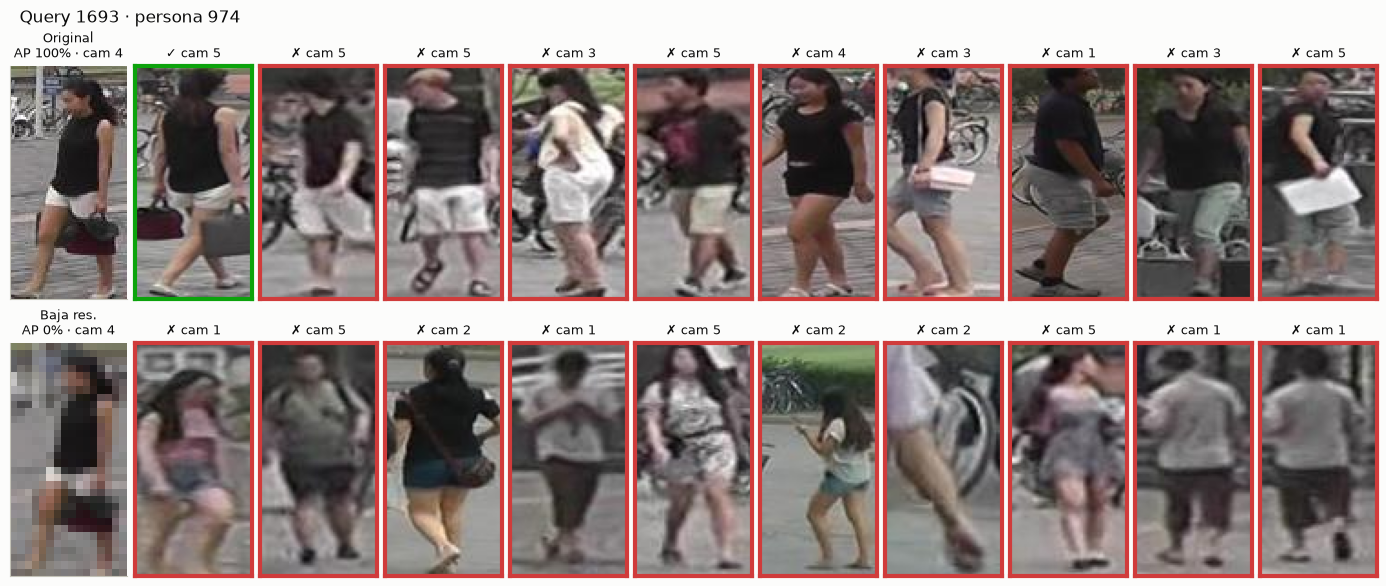

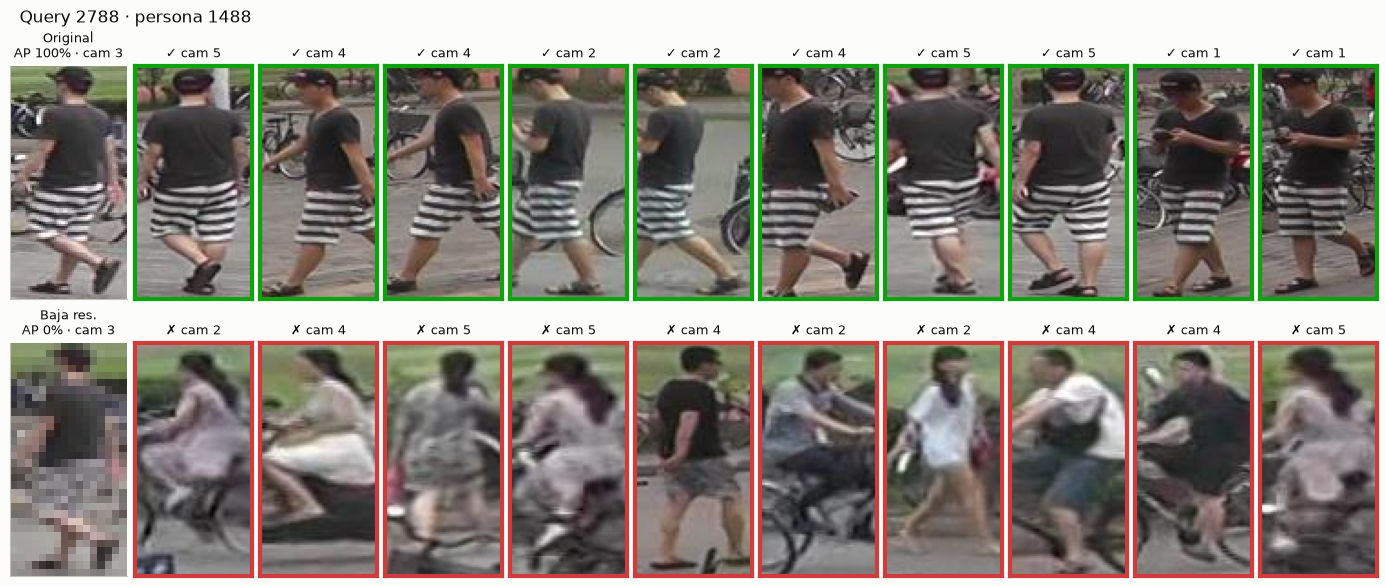

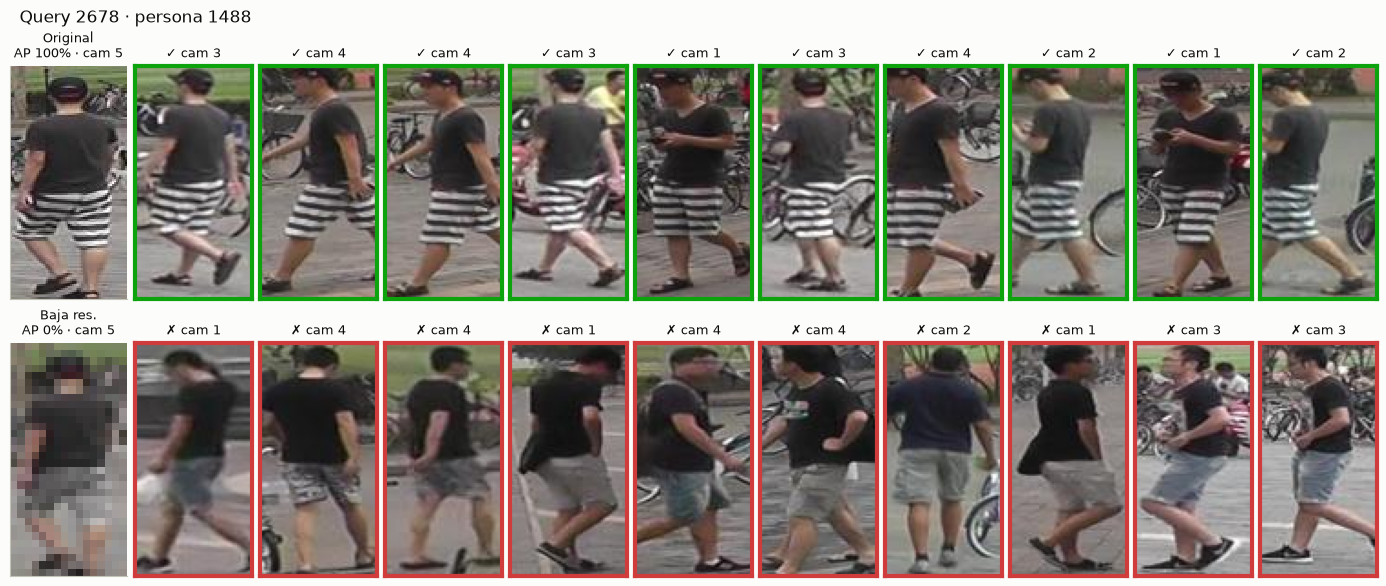

In [16]:
for q_index in valid_indices[np.argsort(-ap_drop, kind="stable")[:3]]:
    show_rankings(q_index)

Queries con peor AP incluso en resolución original:

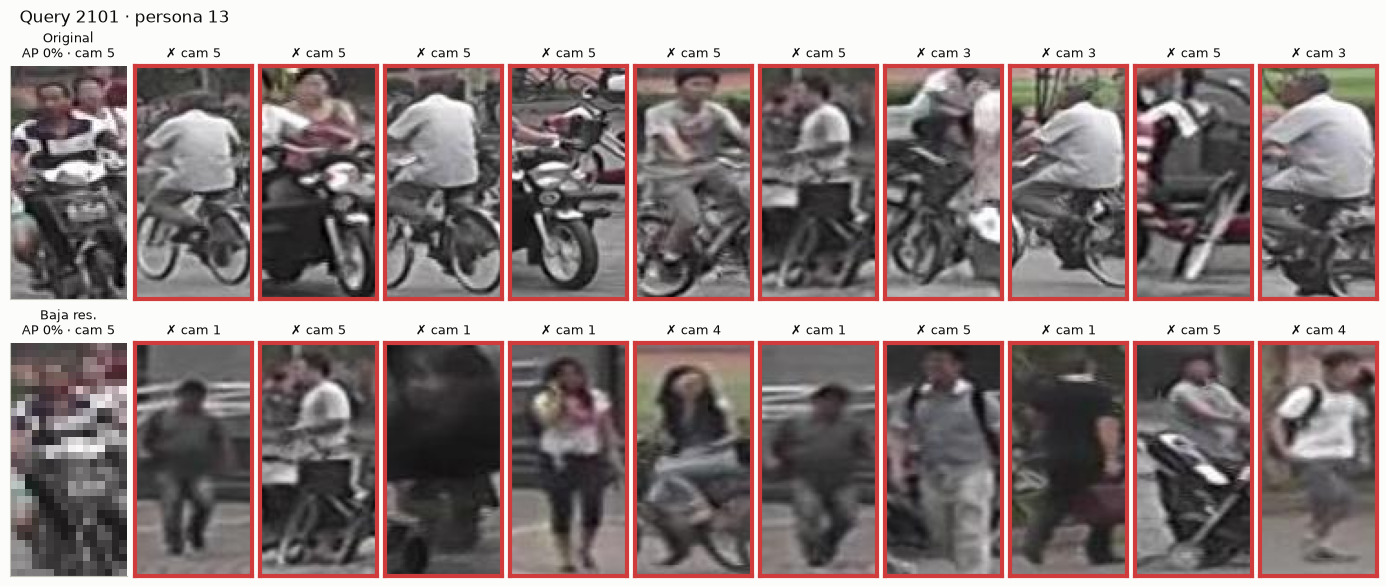

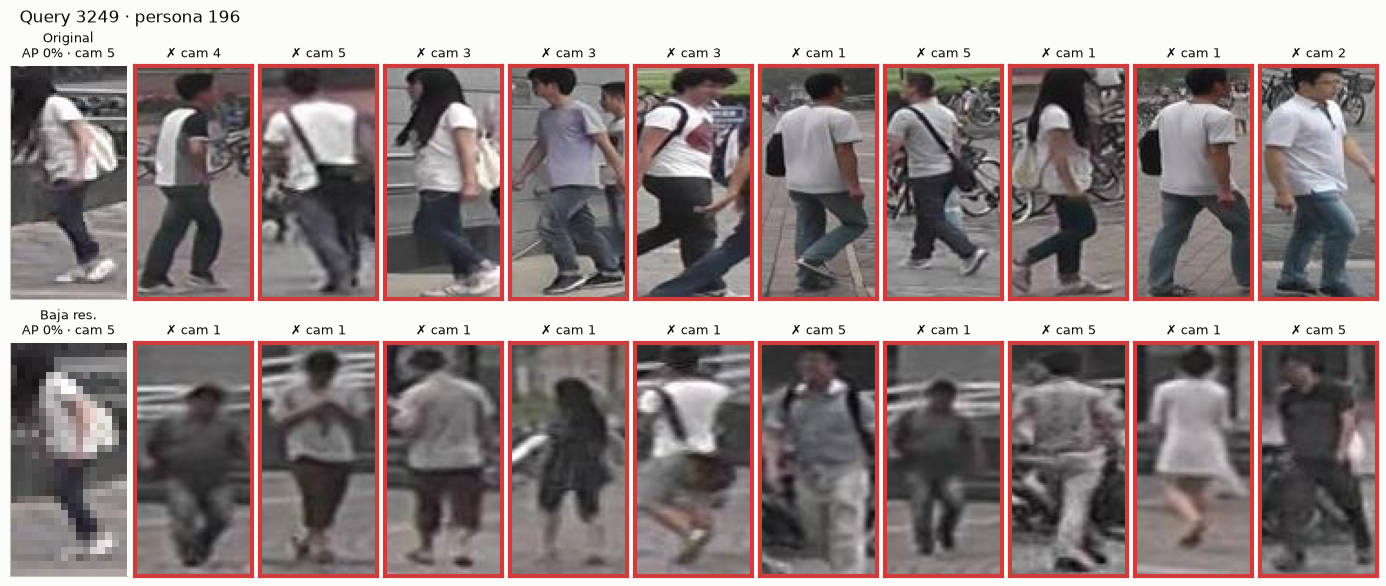

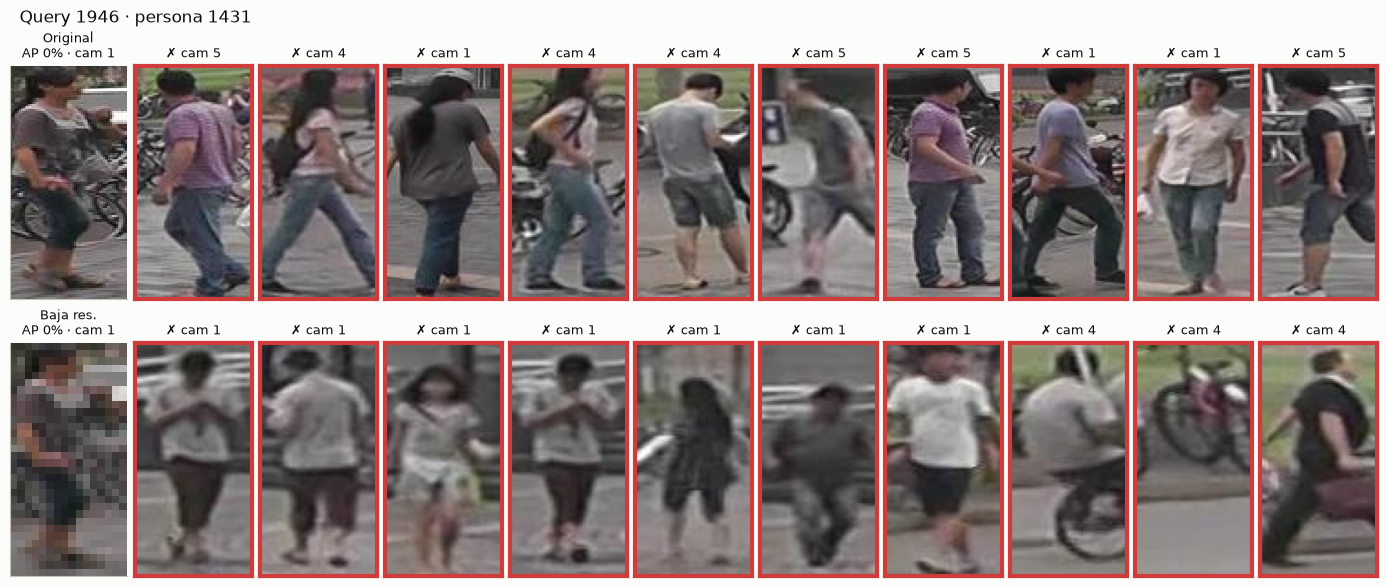

In [17]:
for q_index in valid_indices[np.argsort(ap["query"], kind="stable")[:3]]:
    show_rankings(q_index)

## 5. Tablas para el informe

Markdown listo para copiar en el README.

In [18]:
print("### Validación (mejor época)\n")
print(markdown_table(validation_table(runs)))
print("\n### Test\n")
print(markdown_table(test_rows))

### Validación (mejor época)

| run | variant | epoch | orig mAP | orig rank1 | orig rank5 | orig rank10 | low mAP | low rank1 | low rank5 | low rank10 | mAP drop | drop % |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| abl_no_sa | sin atención espacial | 10 | 28.0% | 42.0% | 57.0% | 66.0% | 15.6% | 26.0% | 39.0% | 46.0% | 12.4 pts | 44.4% |
| abl_no_se | sin SE | 15 | 14.9% | 23.0% | 32.0% | 36.0% | 9.2% | 13.0% | 23.0% | 34.0% | 5.7 pts | 38.4% |
| abl_only_ccl | a=0 | 10 | 15.4% | 27.0% | 43.0% | 47.0% | 8.3% | 12.0% | 23.0% | 36.0% | 7.1 pts | 46.2% |
| ahcl | AHCL (paper) | 20 | 14.7% | 25.0% | 35.0% | 39.0% | 6.0% | 10.0% | 22.0% | 30.0% | 8.7 pts | 59.2% |
| ahcl_256 | 256x128 | 10 | 7.1% | 16.0% | 21.0% | 23.0% | 2.1% | 3.0% | 8.0% | 12.0% | 5.0 pts | 70.5% |
| baseline | sin CAPF, a=1 | 25 | 34.1% | 53.0% | 64.0% | 72.0% | 18.2% | 21.0% | 37.0% | 47.0% | 15.9 pts | 46.7% |
| baseline_256 | sin CAPF, a=1, 256x128 | 35 | 33.2% | 44.0% | 56.0% | 62.0% | 23.0% | 31.0% | 

## 6. Conclusiones

Completar con los resultados de arriba:

- **AHCL frente al modelo base:** diferencia de mAP y Rank-1 en ambas condiciones
  (sección 3).
- **Ablación:** qué componente aporta más y si el efecto supera el ruido de
  validación (secciones 2 y 3).
- **Baja resolución:** caída de mAP, cuántas queries se ven afectadas y si se
  explica por la consistencia del embedding (sección 4).
- **Errores principales:** sesgo de cámara, personas parecidas con ropa similar,
  oclusiones y recortes (ejemplos de la sección 4).
- **Limitaciones:** las del README, actualizadas con lo observado.